In [5]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Visualizando os dados 

In [6]:
candidatos_dados = [Path("dados/bruto"), Path("../dados/bruto")]
caminho_bruto = next((p for p in candidatos_dados if p.is_dir()), None)

if caminho_bruto is None:
    raise FileNotFoundError(
        "Não encontrei a pasta dados/bruto. Execute o notebook a partir da raiz "
        "do projeto ou da pasta notebooks/ e confira a estrutura de pastas."
    )

raiz_projeto = caminho_bruto.parent.parent.resolve()
arquivos_csv = sorted(caminho_bruto.glob("*.csv"))

if not arquivos_csv:
    raise FileNotFoundError(
        f"Nenhum arquivo CSV foi encontrado em: {caminho_bruto.resolve()}"
    )

dfs = []
colunas_padrao = None

for arquivo in arquivos_csv:
    df = pd.read_csv(arquivo, sep=';')

    df.columns = df.columns.astype(str).str.strip()

    print(f"\nArquivo: {arquivo.name} | {df.shape[0]:,} linhas, {df.shape[1]} colunas")
    display(df.head(2))

    colunas_atuais = list(df.columns)
    if colunas_padrao is None:
        colunas_padrao = colunas_atuais
    elif colunas_padrao != colunas_atuais:
        raise ValueError(
            f"O arquivo {arquivo.name} tem colunas diferentes dos demais. "
            "Confira os arquivos antes de concatená-los."
        )

    dfs.append(df)

df_unificado = pd.concat(dfs, ignore_index=True)
print(f"\nArquivos unidos com sucesso. Dimensões: {df_unificado.shape}")
display(df_unificado.head())



Arquivo: Preços semestrais - AUTOMOTIVOS_2024.01.csv | 477,154 linhas, 16 colunas


,Regiao - Sigla,Estado - Sigla,Municipio,Revenda,CNPJ da Revenda,Nome da Rua,Numero Rua,Complemento,Bairro,Cep,Produto,Data da Coleta,Valor de Venda,Valor de Compra,Unidade de Medida,Bandeira
0,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,GASOLINA,01/01/2024,"5,68",NaN,R$ / litro,VIBRA
1,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,GASOLINA ADITIVADA,01/01/2024,"5,68",NaN,R$ / litro,VIBRA



Arquivo: Preços semestrais - AUTOMOTIVOS_2024.02.csv | 421,382 linhas, 16 colunas


,Regiao - Sigla,Estado - Sigla,Municipio,Revenda,CNPJ da Revenda,Nome da Rua,Numero Rua,Complemento,Bairro,Cep,Produto,Data da Coleta,Valor de Venda,Valor de Compra,Unidade de Medida,Bandeira
0,N,AC,RIO BRANCO,CODEPE COMBUSTIVEIS LTDA,08.220.930/0001-62,RODOVIA BR-364 (RIO BRANCO-CRUZEIRO DO SUL) - ...,2755,LOTE 01/02/03/04/05 E 33,PORTAL DA AMAZONIA,69915-630,GASOLINA,01/07/2024,"6,79",NaN,R$ / litro,VIBRA
1,N,AC,RIO BRANCO,CODEPE COMBUSTIVEIS LTDA,08.220.930/0001-62,RODOVIA BR-364 (RIO BRANCO-CRUZEIRO DO SUL) - ...,2755,LOTE 01/02/03/04/05 E 33,PORTAL DA AMAZONIA,69915-630,GASOLINA ADITIVADA,01/07/2024,"6,84",NaN,R$ / litro,VIBRA


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_12984\1139284198.py:22: DtypeWarning: Columns (0: Regiao - Sigla, 1: Estado - Sigla, 2: Municipio, 3: Revenda, 4: CNPJ da Revenda, 5: Nome da Rua, 6: Numero Rua, 7: Complemento, 8: Bairro, 9: Cep, 10: Produto, 11: Data da Coleta, 12: Valor de Venda, 14: Unidade de Medida, 15: Bandeira) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(arquivo, sep=';')


...

,Regiao - Sigla,Estado - Sigla,Municipio,Revenda,CNPJ da Revenda,Nome da Rua,Numero Rua,Complemento,Bairro,Cep,Produto,Data da Coleta,Valor de Venda,Valor de Compra,Unidade de Medida,Bandeira
0,NE,AL,DELMIRO GOUVEIA,COMERCIO DE COMBUSTIVEIS NENZITA LTDA,4431113000100,AVENIDA CAXANGA,126,NaN,PEDRA VELHA,57480-000,DIESEL,01/07/2025,"6,69",NaN,R$ / litro,BRANCA
1,N,AP,MACAPA,SEPE TIARAJU EMPREENDIMENTOS LTDA,5297501000286,RUA SETENTRIONAL,S/N,ESQUINA COM BEIRA RIO,ARAXÁ,68903-640,DIESEL,01/07/2025,"6,33",NaN,R$ / litro,BRANCA



Arquivo: Preços semestrais - AUTOMOTIVOS_2026.01.csv | 422,418 linhas, 16 colunas


,Regiao - Sigla,Estado - Sigla,Municipio,Revenda,CNPJ da Revenda,Nome da Rua,Numero Rua,Complemento,Bairro,Cep,Produto,Data da Coleta,Valor de Venda,Valor de Compra,Unidade de Medida,Bandeira
0,N,AC,CRUZEIRO DO SUL,AMAZONIA COMERCIO DE DERIVADOS DE PETROLEO LTDA,01.492.748/0003-83,AVENIDA COPACABANA,440,NaN,COPACABANA,69980-000,GASOLINA,02/01/2026,"7,97",NaN,R$ / litro,IPIRANGA
1,N,AC,CRUZEIRO DO SUL,AMAZONIA COMERCIO DE DERIVADOS DE PETROLEO LTDA,01.492.748/0003-83,AVENIDA COPACABANA,440,NaN,COPACABANA,69980-000,DIESEL,02/01/2026,"8,15",NaN,R$ / litro,IPIRANGA



Arquivos unidos com sucesso. Dimensões: (2134685, 16)


,Regiao - Sigla,Estado - Sigla,Municipio,Revenda,CNPJ da Revenda,Nome da Rua,Numero Rua,Complemento,Bairro,Cep,Produto,Data da Coleta,Valor de Venda,Valor de Compra,Unidade de Medida,Bandeira
0,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,GASOLINA,01/01/2024,"5,68",NaN,R$ / litro,VIBRA
1,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,GASOLINA ADITIVADA,01/01/2024,"5,68",NaN,R$ / litro,VIBRA
2,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,DIESEL S10,01/01/2024,"5,93",NaN,R$ / litro,VIBRA
3,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,ETANOL,01/01/2024,"3,99",NaN,R$ / litro,VIBRA
4,NE,AL,ARAPIRACA,AUTO POSTO SAO FRANCISCO LTDA,12.706.529/0001-04,RUA SAO FRANCISCO,274,NaN,CENTRO,57300-080,GASOLINA,01/01/2024,"5,48",NaN,R$ / litro,VIBRA


In [7]:
linhas, colunas = df_unificado.shape
linhas_duplicadas = df_unificado.duplicated().sum()

print("="*50)
print(" INSPEÇÃO GERAL DO DATASET")
print("="*50)
print(f"Dimensões globais : {linhas} linhas e {colunas} colunas")
print(f"Linhas duplicadas : {linhas_duplicadas} ocorrencias exatas")
print("="*50 + "\n")

inspecao = pd.DataFrame({
    'Tipo': df_unificado.dtypes,
    'Ausências (Qtd)': df_unificado.isnull().sum(),
    'Ausências (%)': (df_unificado.isnull().sum() / linhas) * 100,
    'Chaves/Únicos': df_unificado.nunique()
})

amostras = []
for col in df_unificado.columns:
    valores = df_unificado[col].dropna().unique()
    amostra_str = ", ".join(map(str, valores[:3]))
    if len(valores) > 3:
        amostra_str += ", ..."
    amostras.append(amostra_str)

inspecao['Categorias (Amostras)'] = amostras

inspecao['Ausências (%)'] = inspecao['Ausências (%)'].round(2).astype(str) + '%'

inspecao = inspecao.sort_values(by='Ausências (Qtd)', ascending=False)

display(inspecao)

 INSPEÇÃO GERAL DO DATASET
Dimensões globais : 2134685 linhas e 16 colunas
Linhas duplicadas : 9129 ocorrencias exatas



,Tipo,Ausências (Qtd),Ausências (%),Chaves/Únicos,Categorias (Amostras)
Valor de Compra,float64,2134685,100.0%,0,
Complemento,str,1649676,77.28%,2362,"KM 70, LOTE 12 QUADRAB, L..."
Bairro,str,12807,0.6%,5511,"SANTA ESMERALDA, CENTRO, CANAFISTULA, ..."
Numero Rua,str,9367,0.44%,4158,"1901, 274, 678, ..."
Revenda,str,9114,0.43%,11558,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...
Municipio,str,9114,0.43%,461,"ARAPIRACA, RIO LARGO, VERA CRUZ, ..."
Regiao - Sigla,str,9114,0.43%,5,"NE, SE, S, ..."
Estado - Sigla,str,9114,0.43%,27,"AL, BA, MA, ..."
CNPJ da Revenda,object,9114,0.43%,20767,"02.817.655/0001-82, 12.706.529/0001-04, 01...."
Nome da Rua,str,9114,0.43%,8189,"RODOVIA AL-220, RUA SAO FRANCISCO, RODOVIA AL-..."


# **Limpeza e Normalização dos Dados (Limpar)**

   Nesta etapa, foram realizados ajustes na base de dados unificada, com foco na correção de inconsistências, padronização das informações e tratamento de valores ausentes.

**Padronização dos Nomes das Colunas:**

   Os nomes das colunas foram convertidos para o padrão snake_case, utilizando letras minúsculas e substituindo espaços e hífens por underscores (_). Essa alteração manteve a nomenclatura uniforme em toda a base.

**Remoção de Duplicidades:**

   Foram removidos os registros completamente duplicados, identificados durante a inspeção inicial dos dados, evitando a repetição de informações nas análises.

**Tratamento de Identificadores e Valores Monetários:**

   Na coluna valor_de_venda, foi realizada a substituição da vírgula pelo ponto como separador decimal, seguida da conversão dos valores para o tipo numérico float64.
   Já nas colunas cnpj_da_revenda e cep, foram removidos caracteres especiais, como pontos, barras e hífens, mantendo apenas os dígitos dos identificadores.

**Padronização de Categorias e Unidades de Medida:**

   Na coluna unidade_de_medida, foram corrigidas diferenças de escrita, como a substituição de m3 por m³.
   Além disso, os valores das colunas de texto foram convertidos para letras minúsculas, mantendo um padrão único para os registros categóricos.

**Tratamento de Datas:**

   A coluna data_da_coleta foi convertida para o formato de data, retirando a exibição do horário (00:00:00). Os registros sem informação de data foram mantidos como NaT, preservando a identificação dos valores ausentes.
   
**Tratamento de Valores Ausentes:**

   Os valores ausentes da coluna numérica valor_de_compra foram preenchidos com 0. Para as colunas de texto, os registros nulos foram substituídos pela expressão "não consta", permitindo identificar as informações que não estavam disponíveis na base.

In [8]:
df_unificado.columns = (
    df_unificado.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(' - ', '_', regex=False)
    .str.replace(' ', '_', regex=False)
    .str.replace('-', '_', regex=False)
)

linhas_antes = len(df_unificado)
df_unificado = df_unificado.drop_duplicates().copy()
print(f"Duplicidades exatas removidas: {linhas_antes - len(df_unificado):,}")

def converter_valor_monetario(serie):
    valores = serie.astype('string').str.strip()
    tem_virgula = valores.str.contains(',', regex=False, na=False)

    valores.loc[tem_virgula] = (
        valores.loc[tem_virgula]
        .str.replace('.', '', regex=False)
        .str.replace(',', '.', regex=False)
    )
    return pd.to_numeric(valores, errors='coerce')

for coluna in ['valor_de_venda', 'valor_de_compra']:
    if coluna in df_unificado.columns:
        df_unificado[coluna] = converter_valor_monetario(df_unificado[coluna])

for coluna in ['cnpj_da_revenda', 'cep']:
    if coluna in df_unificado.columns:
        identificador = df_unificado[coluna].astype('string').str.replace(r'\D', '', regex=True)
        df_unificado[coluna] = identificador.replace('', pd.NA)

if 'unidade_de_medida' in df_unificado.columns:
    df_unificado['unidade_de_medida'] = (
        df_unificado['unidade_de_medida']
        .astype('string').str.strip().str.lower()
        .str.replace('m3', 'm³', regex=False)
    )

if 'data_da_coleta' in df_unificado.columns:
    df_unificado['data_da_coleta'] = pd.to_datetime(
        df_unificado['data_da_coleta'], dayfirst=True, errors='coerce'
    ).dt.normalize()

colunas_texto = df_unificado.select_dtypes(include=['object', 'string']).columns
for coluna in colunas_texto:
    df_unificado[coluna] = (
        df_unificado[coluna].astype('string').str.strip().str.lower())
    df_unificado[coluna] = df_unificado[coluna].replace('nan', np.nan)

print("\nLimpeza concluída.")
print(f"Dimensões após limpeza: {df_unificado.shape[0]:,} linhas e {df_unificado.shape[1]} colunas")
print("\nAusências restantes por coluna:")
display(df_unificado.isna().sum().sort_values(ascending=False).to_frame('quantidade_ausente'))
display(df_unificado.head())


Duplicidades exatas removidas: 9,129

Limpeza concluída.
Dimensões após limpeza: 2,125,556 linhas e 16 colunas

Ausências restantes por coluna:


,quantidade_ausente
valor_de_compra,2125556
complemento,1640547
bairro,3694
numero_rua,254
revenda,1
municipio,1
regiao_sigla,1
estado_sigla,1
cnpj_da_revenda,1
nome_da_rua,1


,regiao_sigla,estado_sigla,municipio,revenda,cnpj_da_revenda,nome_da_rua,numero_rua,complemento,bairro,cep,produto,data_da_coleta,valor_de_venda,valor_de_compra,unidade_de_medida,bandeira
0,ne,al,arapiraca,comercial de combustiveis e lubrificantes vita...,02817655000182,rodovia al-220,1901,<NA>,santa esmeralda,57312025,gasolina,2024-01-01,5.68,<NA>,r$ / litro,vibra
1,ne,al,arapiraca,comercial de combustiveis e lubrificantes vita...,02817655000182,rodovia al-220,1901,<NA>,santa esmeralda,57312025,gasolina aditivada,2024-01-01,5.68,<NA>,r$ / litro,vibra
2,ne,al,arapiraca,comercial de combustiveis e lubrificantes vita...,02817655000182,rodovia al-220,1901,<NA>,santa esmeralda,57312025,diesel s10,2024-01-01,5.93,<NA>,r$ / litro,vibra
3,ne,al,arapiraca,comercial de combustiveis e lubrificantes vita...,02817655000182,rodovia al-220,1901,<NA>,santa esmeralda,57312025,etanol,2024-01-01,3.99,<NA>,r$ / litro,vibra
4,ne,al,arapiraca,auto posto sao francisco ltda,12706529000104,rua sao francisco,274,<NA>,centro,57300080,gasolina,2024-01-01,5.48,<NA>,r$ / litro,vibra


# 5. Transformação dos Dados (Transformar)

    Nesta etapa, foram realizadas transformações na base de dados para facilitar as análises e permitir uma melhor organização das informações. Além dos ajustes de consistência, foram criadas novas variáveis e uma visão agregada dos dados.

    Filtragem de Consistência

    Foram removidos os registros que apresentavam valores de venda iguais ou inferiores a zero, considerando que esses valores poderiam representar inconsistências na coleta e comprometer os resultados das análises estatísticas.

    Criação das Variáveis ano_coleta e mes_coleta

    A partir da data de coleta, foram extraídos o ano e o mês de cada registro. Essa separação permite acompanhar as variações dos preços ao longo do tempo, facilitando a identificação de padrões e possíveis comportamentos sazonais.

    Criação da Variável tipo_bandeira

    Os postos foram classificados em duas categorias: independente, para postos de bandeira branca, e rede_franqueada, para os demais. Essa divisão permite comparar os preços praticados pelos diferentes tipos de estabelecimento e identificar possíveis diferenças entre eles.

    Criação da Variável faixa_de_preco

    Os valores de venda foram agrupados em três categorias: baixo, médio e alto, utilizando os quartis como referência. Essa classificação facilita a comparação entre diferentes regiões e a identificação de locais com maior concentração de preços elevados ou reduzidos.

Criação da Visão Agregada (Resumo Estatístico)

Foi criada uma base resumida com o agrupamento dos dados por estado e produto, considerando a média, mediana, valores máximo e mínimo dos preços de venda, além da quantidade de revendas distintas (quantidade_revendas_distintas).

Como a base original possui mais de 2 milhões de registros, essa agregação permite realizar consultas de forma mais prática, reduzindo a necessidade de processar todos os registros em cada análise. Além disso, a estrutura facilita a construção de visualizações e dashboards no Power BI.

In [9]:
df_transformado = df_unificado.copy()

df_transformado['data_da_coleta'] = pd.to_datetime(
    df_transformado['data_da_coleta'], dayfirst=True, errors='coerce'
).dt.normalize()
df_transformado['valor_de_venda'] = pd.to_numeric(
    df_transformado['valor_de_venda'], errors='coerce'
)

linhas_antes = len(df_transformado)
df_transformado = df_transformado.dropna(
    subset=['data_da_coleta', 'valor_de_venda']
).copy()
df_transformado = df_transformado.loc[
    df_transformado['valor_de_venda'] > 0
].copy()
print(f"Registros removidos por data/preço ausente ou preço não positivo: "
      f"{linhas_antes - len(df_transformado):,}")

df_transformado['ano_coleta'] = df_transformado['data_da_coleta'].dt.year
df_transformado['mes_coleta'] = df_transformado['data_da_coleta'].dt.month

if 'bandeira' in df_transformado.columns:
    bandeira = df_transformado['bandeira'].astype('string').fillna('não consta')
    df_transformado['tipo_bandeira'] = np.select(
        [bandeira.eq('branca'), bandeira.eq('não consta')],
        ['independente', 'não consta'],
        default='rede_franqueada'
    )
else:
    raise KeyError("A coluna 'bandeira' não foi encontrada na base.")

try:
    df_transformado['faixa_de_preco'] = pd.qcut(
        df_transformado['valor_de_venda'],
        q=3,
        labels=['baixo', 'médio', 'alto'],
        duplicates='raise'
    )
except ValueError:

    df_transformado['faixa_de_preco'] = pd.cut(
        df_transformado['valor_de_venda'],
        bins=3,
        labels=['baixo', 'médio', 'alto'],
        include_lowest=True
    )

colunas_agregacao = {
    'preco_medio': ('valor_de_venda', 'mean'),
    'preco_mediano': ('valor_de_venda', 'median'),
    'preco_maximo': ('valor_de_venda', 'max'),
    'preco_minimo': ('valor_de_venda', 'min')
}
if 'cnpj_da_revenda' in df_transformado.columns:
    colunas_agregacao['quantidade_revendas_distintas'] = ('cnpj_da_revenda', 'nunique')

df_agregado = (
    df_transformado.groupby(['estado_sigla', 'produto'])
    .agg(**colunas_agregacao)
    .reset_index()
)
colunas_moeda = ['preco_medio', 'preco_mediano', 'preco_maximo', 'preco_minimo']
df_agregado[colunas_moeda] = df_agregado[colunas_moeda].round(2)

print("Transformações aplicadas com sucesso!")
print(f"Dimensões da base transformada: {df_transformado.shape[0]:,} linhas e {df_transformado.shape[1]} colunas")
display(df_transformado[['data_da_coleta', 'ano_coleta', 'mes_coleta', 'bandeira', 'tipo_bandeira', 'valor_de_venda', 'faixa_de_preco']].head())
print("\nVisão agregada por estado e produto:")
display(df_agregado.head())

caminho_salvamento = raiz_projeto / 'dados' / 'processado' / 'base_anp_transformada.csv'
caminho_salvamento.parent.mkdir(parents=True, exist_ok=True)
df_transformado.to_csv(caminho_salvamento, index=False)
print(f"Base processada salva em: {caminho_salvamento}")


Registros removidos por data/preço ausente ou preço não positivo: 1
Transformações aplicadas com sucesso!
Dimensões da base transformada: 2,125,555 linhas e 20 colunas


,data_da_coleta,ano_coleta,mes_coleta,bandeira,tipo_bandeira,valor_de_venda,faixa_de_preco
0,2024-01-01,2024,1,vibra,rede_franqueada,5.68,baixo
1,2024-01-01,2024,1,vibra,rede_franqueada,5.68,baixo
2,2024-01-01,2024,1,vibra,rede_franqueada,5.93,médio
3,2024-01-01,2024,1,vibra,rede_franqueada,3.99,baixo
4,2024-01-01,2024,1,vibra,rede_franqueada,5.48,baixo



Visão agregada por estado e produto:


,estado_sigla,produto,preco_medio,preco_mediano,preco_maximo,preco_minimo,quantidade_revendas_distintas
0,ac,diesel,7.58,7.55,8.77,6.79,47
1,ac,diesel s10,7.64,7.65,9.27,6.89,46
2,ac,etanol,5.24,5.24,7.44,4.49,32
3,ac,gasolina,7.39,7.39,8.5,6.49,51
4,ac,gasolina aditivada,7.44,7.45,8.59,6.51,47


Base processada salva em: C:\Users\Lenovo\Downloads\pro_ML_VD\dados\processado\base_anp_transformada.csv


In [10]:
estatisticas_regiao = (
    df_transformado
    .groupby(['regiao_sigla', 'produto'])
    .agg(
        quantidade=('valor_de_venda', 'count'),
        preco_medio=('valor_de_venda', 'mean'),
        mediana=('valor_de_venda', 'median'),
        minimo=('valor_de_venda', 'min'),
        maximo=('valor_de_venda', 'max'),
        desvio_padrao=('valor_de_venda', 'std')
    )
    .round(2)
    .reset_index()
)

display(estatisticas_regiao)

,regiao_sigla,produto,quantidade,preco_medio,mediana,minimo,maximo,desvio_padrao
0,co,diesel,23647,6.15,5.99,5.19,8.89,0.51
1,co,diesel s10,28665,6.23,6.09,5.18,8.91,0.52
2,co,etanol,38733,4.17,4.09,2.67,5.89,0.48
3,co,gasolina,45034,6.19,6.19,4.79,7.55,0.39
4,co,gasolina aditivada,29633,6.35,6.39,4.85,8.99,0.41
5,co,gnv,368,4.26,4.09,3.54,6.69,0.51
6,n,diesel,21559,6.62,6.49,4.69,8.77,0.59
7,n,diesel s10,29604,6.61,6.49,4.99,9.29,0.66
8,n,etanol,20174,4.94,4.99,3.39,7.44,0.5
9,n,gasolina,39319,6.61,6.62,4.74,9.29,0.6


**Particionamento dos Dados (Particionar)**

  A base de dados foi dividida em três subconjuntos: treino, validação e teste, seguindo uma ordem cronológica para preservar a sequência temporal dos registros.

  Para isso, os dados foram organizados pela data de coleta e divididos sequencialmente, sem a utilização de embaralhamento aleatório (shuffle=False). A distribuição foi realizada da seguinte forma:

**Treino (70%)**

  Composto por 1.487.888 registros, abrangendo o período de 01/01/2024 a 24/09/2025. Esse conjunto foi destinado ao treinamento do modelo, utilizando os dados do período mais antigo.

**Validação (15%)**

  Composto por 318.833 registros, correspondentes ao período de 24/09/2025 a 16/02/2026. Essa parcela foi reservada para acompanhar o desempenho do modelo durante o desenvolvimento e realizar os ajustes necessários nos hiperparâmetros.

**Teste (15%)**

  Composto por 318.834 registros, abrangendo o período de 16/02/2026 a 30/06/2026. Esse conjunto foi reservado para a avaliação final do modelo, utilizando os registros mais recentes da base.

**Justificativa do Particionamento**

  A divisão cronológica foi adotada considerando as variações dos preços dos combustíveis ao longo do tempo. Um particionamento aleatório poderia misturar informações de diferentes períodos, permitindo que dados mais recentes influenciassem o treinamento destinado a prever períodos anteriores.

  Dessa forma, a separação temporal reduz o risco de vazamento de dados (Data Leakage) e permite avaliar o desempenho do modelo em períodos posteriores aos utilizados no treinamento.

  Além disso, a divisão mantém os dados de teste separados das etapas de treinamento e validação, possibilitando uma avaliação mais adequada da capacidade de generalização do modelo.

In [11]:
df_modelagem = df_transformado.sort_values('data_da_coleta').reset_index(drop=True).copy()
df_modelagem['data_da_coleta'] = pd.to_datetime(
    df_modelagem['data_da_coleta'], errors='coerce'
).dt.normalize()
df_modelagem = df_modelagem.dropna(
    subset=['data_da_coleta', 'valor_de_venda']
).copy()

datas_unicas = np.sort(df_modelagem['data_da_coleta'].unique())
if len(datas_unicas) < 10:
    raise ValueError(
        f"A partição temporal requer pelo menos 10 datas distintas; foram encontradas {len(datas_unicas)}."
    )

n_datas = len(datas_unicas)
n_datas_treino = int(np.floor(n_datas * 0.70))
n_datas_validacao = int(np.floor(n_datas * 0.85))
n_datas_treino = max(1, n_datas_treino)
n_datas_validacao = max(n_datas_treino + 1, n_datas_validacao)
n_datas_validacao = min(n_datas_validacao, n_datas - 1)

limite_treino = datas_unicas[n_datas_treino - 1]
limite_validacao = datas_unicas[n_datas_validacao - 1]

datas = df_modelagem['data_da_coleta']
df_treino = df_modelagem.loc[datas <= limite_treino].copy().reset_index(drop=True)
df_val = df_modelagem.loc[
    (datas > limite_treino) & (datas <= limite_validacao)
].copy().reset_index(drop=True)
df_teste = df_modelagem.loc[datas > limite_validacao].copy().reset_index(drop=True)

if df_treino.empty or df_val.empty or df_teste.empty:
    raise ValueError("Uma das partições ficou vazia. Confira a cobertura de datas da base.")

colunas_excluir = [
    'valor_de_venda', 
    'faixa_de_preco', 
    'valor_de_compra', 
    'preco_medio', 
    'preco_mediano', 
    'preco_maximo', 
    'preco_minimo', 
    'quantidade_revendas_distintas'
]

X = df_unificado.drop(columns=colunas_excluir, errors='ignore')
y = df_unificado['valor_de_venda']

X_treino = df_treino.drop(columns=colunas_excluir, errors='ignore')
y_treino = df_treino['valor_de_venda'].reset_index(drop=True)
X_val = df_val.drop(columns=colunas_excluir, errors='ignore')
y_val = df_val['valor_de_venda'].reset_index(drop=True)
X_teste = df_teste.drop(columns=colunas_excluir, errors='ignore')
y_teste = df_teste['valor_de_venda'].reset_index(drop=True)

datas_treino_cv = df_treino['data_da_coleta'].reset_index(drop=True)
datas_teste = df_teste['data_da_coleta'].reset_index(drop=True)

print("Particionamento temporal concluído.")
print(f"Datas distintas: treino={n_datas_treino:,}, validação={n_datas_validacao - n_datas_treino:,}, teste={n_datas - n_datas_validacao:,}")
for nome, parte in [('Treino', df_treino), ('Validação', df_val), ('Teste', df_teste)]:
    print(f"{nome}: {len(parte):,} registros | {parte['data_da_coleta'].min().date()} até {parte['data_da_coleta'].max().date()}")


Particionamento temporal concluído.
Datas distintas: treino=475, validação=103, teste=102
Treino: 1,504,362 registros | 2024-01-01 até 2025-10-01
Validação: 302,446 registros | 2025-10-02 até 2026-02-16
Teste: 318,747 registros | 2026-02-17 até 2026-06-30


 **Referenciar (`Baseline e Métrica Inicial`)**

   Nesta etapa, foi estabelecida a baseline do projeto, utilizando um modelo de referência para comparar o desempenho dos modelos preditivos que serão desenvolvidos posteriormente.

**Construção do Modelo de Referência (Dummy Regressor)**

   Foi utilizado o modelo `DummyRegressor`, configurado para realizar previsões a partir da média aritmética da variável `valor_de_venda`, calculada exclusivamente com os dados do conjunto de treino, correspondente ao período de 01/01/2024 a 24/09/2025.

   Valor obtido foi utilizado como previsão fixa para os registros dos conjuntos de validação e teste, permitindo avaliar o desempenho de uma abordagem simples, sem considerar as características individuais de cada registro.

**Avaliação das Métricas de Erro**

   Para avaliar o desempenho da baseline, foram consideradas duas métricas:

   - **MAE (Erro Médio Absoluto):** utilizado para verificar a diferença média entre os valores previstos e os preços reais dos combustíveis, em reais (R$).
   - **RMSE (Raiz do Erro Quadrático Médio):** utilizado para avaliar os erros das previsões, atribuindo maior peso às diferenças mais elevadas entre os valores previstos e observados.

**Justificativa da Baseline**

   A utilização do `DummyRegressor` permitiu estabelecer um ponto de comparação inicial para os próximos modelos. Dessa forma, será possível verificar se a aplicação de métodos mais avançados apresenta melhorias em relação à previsão baseada apenas na média histórica dos preços.

   Essa comparação também será importante para avaliar se os ganhos de desempenho justificam a utilização de modelos com maior complexidade.

**Relação com os Objetivos do Projeto**

   Para a análise voltada ao consumidor, a baseline estabelece uma referência inicial de erro para as previsões de preços, contribuindo para avaliar a precisão dos modelos que poderão auxiliar na identificação de melhores condições de abastecimento.

   No contexto da Forno Nobre, essa referência também será utilizada para avaliar a precisão das estimativas relacionadas aos custos de combustível. Considerando o impacto dessas despesas na operação de transporte, a redução dos erros de previsão poderá contribuir para um planejamento financeiro mais adequado e um melhor acompanhamento dos custos operacionais.

In [12]:
X_dummy_treino = np.zeros((len(y_treino), 1))
X_dummy_val = np.zeros((len(y_val), 1))
X_dummy_teste = np.zeros((len(y_teste), 1))

modelo_baseline = DummyRegressor(strategy='mean')
modelo_baseline.fit(X_dummy_treino, y_treino)
valor_medio_treino = float(modelo_baseline.constant_[0][0])

predicoes_trivial_val = modelo_baseline.predict(X_dummy_val)
predicoes_trivial_teste = modelo_baseline.predict(X_dummy_teste)

mae_trivial_val = mean_absolute_error(y_val, predicoes_trivial_val)
rmse_trivial_val = np.sqrt(mean_squared_error(y_val, predicoes_trivial_val))
mae_trivial_teste = mean_absolute_error(y_teste, predicoes_trivial_teste)
rmse_trivial_teste = np.sqrt(mean_squared_error(y_teste, predicoes_trivial_teste))

print("BASELINE TRIVIAL — MÉDIA DO TREINO")
print(f"Preço constante previsto: R$ {valor_medio_treino:.4f}")
print(f"Validação — MAE: R$ {mae_trivial_val:.4f} | RMSE: R$ {rmse_trivial_val:.4f}")
print(f"Teste      — MAE: R$ {mae_trivial_teste:.4f} | RMSE: R$ {rmse_trivial_teste:.4f}")

colunas_grupo = ['estado_sigla', 'produto']
for coluna in colunas_grupo:
    if coluna not in X_treino.columns:
        raise KeyError(f"A coluna necessária ao baseline operacional não existe: {coluna}")

base_operacional = X_treino[colunas_grupo].copy().reset_index(drop=True)
for coluna in colunas_grupo:
    base_operacional[coluna] = (
        base_operacional[coluna].astype('string').fillna('não consta')
    )
base_operacional['valor_de_venda'] = y_treino.to_numpy()

medianas_operacionais = (
    base_operacional.groupby(colunas_grupo, dropna=False, as_index=False)
    ['valor_de_venda'].median()
    .rename(columns={'valor_de_venda': 'mediana_historica'})
)
mediana_global_treino = float(y_treino.median())

def prever_baseline_operacional(X_alvo):
    grupos = X_alvo[colunas_grupo].copy().reset_index(drop=True)
    grupos['_ordem_original'] = np.arange(len(grupos))
    for coluna in colunas_grupo:
        grupos[coluna] = grupos[coluna].astype('string').fillna('não consta')
    resultado = grupos.merge(
        medianas_operacionais,
        on=colunas_grupo,
        how='left',
        sort=False,
        validate='many_to_one'
    )
    resultado = resultado.sort_values('_ordem_original')
    return resultado['mediana_historica'].fillna(mediana_global_treino).to_numpy()

predicoes_operacional_val = prever_baseline_operacional(X_val)
predicoes_operacional_teste = prever_baseline_operacional(X_teste)

mae_operacional_val = mean_absolute_error(y_val, predicoes_operacional_val)
rmse_operacional_val = np.sqrt(mean_squared_error(y_val, predicoes_operacional_val))
mae_operacional_teste = mean_absolute_error(y_teste, predicoes_operacional_teste)
rmse_operacional_teste = np.sqrt(mean_squared_error(y_teste, predicoes_operacional_teste))

print("\nBASELINE OPERACIONAL PROPOSTO — MEDIANA POR ESTADO E PRODUTO")
print(f"Validação — MAE: R$ {mae_operacional_val:.4f} | RMSE: R$ {rmse_operacional_val:.4f}")
print(f"Teste      — MAE: R$ {mae_operacional_teste:.4f} | RMSE: R$ {rmse_operacional_teste:.4f}")


BASELINE TRIVIAL — MÉDIA DO TREINO
Preço constante previsto: R$ 5.6781
Validação — MAE: R$ 0.7066 | RMSE: R$ 0.8427
Teste      — MAE: R$ 1.1393 | RMSE: R$ 1.2593

BASELINE OPERACIONAL PROPOSTO — MEDIANA POR ESTADO E PRODUTO
Validação — MAE: R$ 0.2944 | RMSE: R$ 0.3996
Teste      — MAE: R$ 0.7124 | RMSE: R$ 0.8582


# ENTREGA 5

In [13]:


# Definição das features (como tinhas no teu código original)
features_categoricas = ['regiao_sigla', 'estado_sigla', 'produto', 'bandeira', 'tipo_bandeira']
features_numericas = ['ano_coleta', 'mes_coleta']
features_modelo = features_categoricas + features_numericas

X_treino_modelo = X_treino[features_modelo].copy()
X_val_modelo = X_val[features_modelo].copy()
X_teste_modelo = X_teste[features_modelo].copy()

# 1. Configuração do Pipeline (Pré-processador)
pre_processador = ColumnTransformer(
    transformers=[
        ('cat', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='constant', fill_value='nao_consta')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), features_categoricas),
        ('num', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median'))
        ]), features_numericas)
    ], remainder='drop')

# 2. Configuração do Modelo Final
modelo = Pipeline(steps=[
    ('preprocessor', pre_processador),
    ('regressor', DecisionTreeRegressor(random_state=42, max_depth=10))
])

# 3. Validação Cruzada Temporal (TimeSeriesSplit)
tscv = TimeSeriesSplit(n_splits=5)

print("A executar Validação Cruzada Temporal...")
cv_scores_mae = cross_val_score(modelo, X_treino_modelo, y_treino, cv=tscv, scoring='neg_mean_absolute_error')
cv_mae_medio = -cv_scores_mae.mean()
cv_mae_std = cv_scores_mae.std()

print(f"Validação Cruzada (5 divisões) - MAE Médio: R$ {cv_mae_medio:.4f} (Desvio: R$ {cv_mae_std:.4f})\n")

# 4. Treinamento no conjunto de treino completo e Avaliação
modelo.fit(X_treino_modelo, y_treino)
pred_val = modelo.predict(X_val_modelo)

mae_val = mean_absolute_error(y_val, pred_val)
rmse_val = np.sqrt(mean_squared_error(y_val, pred_val))

print("Desempenho no Conjunto de Validação:")
print(f"MAE: R$ {mae_val:.4f}")
print(f"RMSE: R$ {rmse_val:.4f}")

A executar Validação Cruzada Temporal...
Validação Cruzada (5 divisões) - MAE Médio: R$ 0.2809 (Desvio: R$ 0.0356)

Desempenho no Conjunto de Validação:
MAE: R$ 0.2572
RMSE: R$ 0.3426


In [14]:
predicoes_modelo_teste = modelo.predict(X_teste_modelo)
mae_modelo_teste = mean_absolute_error(y_teste, predicoes_modelo_teste)
rmse_modelo_teste = np.sqrt(mean_squared_error(y_teste, predicoes_modelo_teste))


MAE por fold da validação cruzada temporal:
Fold 1: R$ 0.2587
Fold 2: R$ 0.2276
Fold 3: R$ 0.4107
Fold 4: R$ 0.2688
Fold 5: R$ 0.2670
MAE médio CV: R$ 0.2866
Desvio-padrão dos folds: R$ 0.0638

RESUMO DOS RESÍDUOS NO TESTE
Média dos resíduos: R$ 0.4502
Mediana dos resíduos: R$ 0.4099
Desvio-padrão dos resíduos: R$ 0.5351
Maior erro absoluto: R$ 3.7099

10 observações com maior erro absoluto:


,data,preco_real,preco_previsto,residuo,erro_absoluto
189763,2026-05-07,9.99,6.2801,3.7099,3.7099
190398,2026-05-07,9.99,6.2801,3.7099,3.7099
205352,2026-05-14,9.99,6.2801,3.7099,3.7099
205440,2026-05-14,9.99,6.2801,3.7099,3.7099
222053,2026-05-21,9.99,6.2801,3.7099,3.7099
285521,2026-06-17,9.99,6.2801,3.7099,3.7099
285634,2026-06-17,9.99,6.2801,3.7099,3.7099
313325,2026-06-30,9.79,6.1864,3.6036,3.6036
52400,2026-03-10,9.68,6.1516,3.5284,3.5284
175404,2026-05-04,9.79,6.2801,3.5099,3.5099


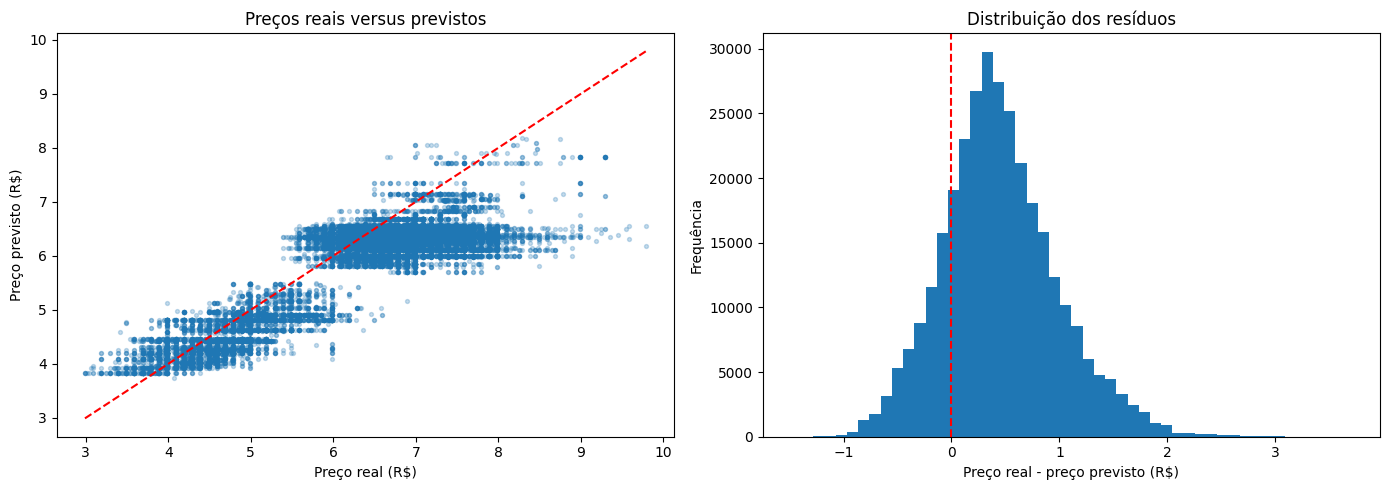

In [15]:
datas_treino_normalizadas = pd.to_datetime(datas_treino_cv).dt.normalize().reset_index(drop=True)
dias_treino_unicos = np.sort(datas_treino_normalizadas.unique())
if len(dias_treino_unicos) < 6:
    raise ValueError("A validação cruzada com 5 folds exige pelo menos 6 datas distintas no treino.")

ts_cv = TimeSeriesSplit(n_splits=5)
cv_splits = []
for idx_dias_treino, idx_dias_validacao in ts_cv.split(dias_treino_unicos):
    dias_fold_treino = dias_treino_unicos[idx_dias_treino]
    dias_fold_validacao = dias_treino_unicos[idx_dias_validacao]
    linhas_treino = np.flatnonzero(
        datas_treino_normalizadas.isin(dias_fold_treino).to_numpy()
    )
    linhas_validacao = np.flatnonzero(
        datas_treino_normalizadas.isin(dias_fold_validacao).to_numpy()
    )
    cv_splits.append((linhas_treino, linhas_validacao))

scores_cv = cross_val_score(
    modelo, # Corrigido: antes estava pipeline_modelo
    X_treino_modelo.reset_index(drop=True),
    y_treino.reset_index(drop=True),
    cv=cv_splits,
    scoring='neg_mean_absolute_error',
    n_jobs=1
)
mae_cv_por_fold = -scores_cv
print("\nMAE por fold da validação cruzada temporal:")
for numero, score in enumerate(mae_cv_por_fold, start=1):
    print(f"Fold {numero}: R$ {score:.4f}")
print(f"MAE médio CV: R$ {mae_cv_por_fold.mean():.4f}")
print(f"Desvio-padrão dos folds: R$ {mae_cv_por_fold.std():.4f}")

valores_reais = y_teste.to_numpy()
residuos = valores_reais - predicoes_modelo_teste
erros_absolutos = np.abs(residuos)

print("\nRESUMO DOS RESÍDUOS NO TESTE")
print(f"Média dos resíduos: R$ {residuos.mean():.4f}")
print(f"Mediana dos resíduos: R$ {np.median(residuos):.4f}")
print(f"Desvio-padrão dos resíduos: R$ {residuos.std():.4f}")
print(f"Maior erro absoluto: R$ {erros_absolutos.max():.4f}")

diagnostico_residuos = pd.DataFrame({
    'data': pd.to_datetime(datas_teste).dt.date.to_numpy(),
    'preco_real': valores_reais,
    'preco_previsto': predicoes_modelo_teste,
    'residuo': residuos,
    'erro_absoluto': erros_absolutos
})
print("\n10 observações com maior erro absoluto:")
display(diagnostico_residuos.nlargest(10, 'erro_absoluto').round(4))

quantidade_pontos = min(30000, len(valores_reais))
indices_plot = np.random.default_rng(42).choice(
    len(valores_reais), size=quantidade_pontos, replace=False
)
reais_plot = valores_reais[indices_plot]
previstos_plot = predicoes_modelo_teste[indices_plot]

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
eixos[0].scatter(reais_plot, previstos_plot, alpha=0.25, s=8)
limite_minimo = min(reais_plot.min(), previstos_plot.min())
limite_maximo = max(reais_plot.max(), previstos_plot.max())
eixos[0].plot(
    [limite_minimo, limite_maximo],
    [limite_minimo, limite_maximo],
    'r--'
)
eixos[0].set_title('Preços reais versus previstos')
eixos[0].set_xlabel('Preço real (R$)')
eixos[0].set_ylabel('Preço previsto (R$)')

eixos[1].hist(residuos, bins=50)
eixos[1].axvline(0, color='red', linestyle='--')
eixos[1].set_title('Distribuição dos resíduos')
eixos[1].set_xlabel('Preço real - preço previsto (R$)')
eixos[1].set_ylabel('Frequência')
plt.tight_layout()
plt.show()

Comparação final das abordagens
A célula seguinte compara os dois baselines e o primeiro modelo usando as mesmas observações do conjunto de teste e as mesmas métricas.

In [16]:
tabela_comparacao = pd.DataFrame([
    {
        'Abordagem': 'Baseline trivial',
        'MAE (R$)': mae_trivial_teste,
        'RMSE (R$)': rmse_trivial_teste,
        'Observação': 'Prevê a média dos preços de treino'
    },
    {
        'Abordagem': 'Baseline operacional proposto',
        'MAE (R$)': mae_operacional_teste,
        'RMSE (R$)': rmse_operacional_teste,
        'Observação': 'Mediana histórica por estado e produto'
    },
    {
        'Abordagem': 'Árvore de decisão',
        'MAE (R$)': mae_modelo_teste,
        'RMSE (R$)': rmse_modelo_teste,
        'Observação': 'Primeiro modelo supervisionado'
    }
])

print('COMPARAÇÃO NO MESMO CONJUNTO DE TESTE')
display(tabela_comparacao.round(4))

COMPARAÇÃO NO MESMO CONJUNTO DE TESTE


,Abordagem,MAE (R$),RMSE (R$),Observação
0,Baseline trivial,1.1393,1.2593,Prevê a média dos preços de treino
1,Baseline operacional proposto,0.7124,0.8582,Mediana histórica por estado e produto
2,Árvore de decisão,0.5507,0.6993,Primeiro modelo supervisionado


# Diagnóstico documentado de vazamento de dados
A classificação abaixo é preliminar e deve ser validada em relação ao momento operacional exato da previsão. “Condicional” significa que a variável só deve ser usada se já estiver disponível no instante em que a previsão seria feita.

In [17]:
auditoria_vazamento = pd.DataFrame([
    {
        'Variável': 'regiao_sigla',
        'Classificação': 'Permitida se conhecida no corte',
        'Justificativa': 'Característica geográfica conhecida antes da previsão.'
    },
    {
        'Variável': 'estado_sigla',
        'Classificação': 'Permitida se conhecido no corte',
        'Justificativa': 'Localização da revenda pode ser conhecida previamente.'
    },
    {
        'Variável': 'produto',
        'Classificação': 'Permitida se conhecido no corte',
        'Justificativa': 'O combustível cuja cotação será estimada pode ser definido antes da previsão.'
    },
    {
        'Variável': 'bandeira',
        'Classificação': 'Condicional',
        'Justificativa': 'Só pode ser usada se a bandeira da revenda for conhecida no instante da previsão.'
    },
    {
        'Variável': 'ano_coleta / mes_coleta',
        'Classificação': 'Condicional',
        'Justificativa': 'O calendário do período previsto deve ser conhecido previamente e coerente com o horizonte.'
    },
    {
        'Variável': 'valor_de_compra',
        'Classificação': 'Excluída das features',
        'Justificativa': 'Não foi assumida como disponível no momento da previsão; foi removida de X.'
    },
    {
        'Variável': 'valor_de_venda',
        'Classificação': 'Proibida como preditora',
        'Justificativa': 'É o próprio alvo previsto e só é usado como y.'
    },
    {
        'Variável': 'faixa_de_preco',
        'Classificação': 'Proibida como preditora',
        'Justificativa': 'É derivada diretamente de valor_de_venda e, por isso, carrega informação do alvo.'
    }
])

display(auditoria_vazamento)

,Variável,Classificação,Justificativa
0,regiao_sigla,Permitida se conhecida no corte,Característica geográfica conhecida antes da p...
1,estado_sigla,Permitida se conhecido no corte,Localização da revenda pode ser conhecida prev...
2,produto,Permitida se conhecido no corte,O combustível cuja cotação será estimada pode ...
3,bandeira,Condicional,Só pode ser usada se a bandeira da revenda for...
4,ano_coleta / mes_coleta,Condicional,O calendário do período previsto deve ser conh...
5,valor_de_compra,Excluída das features,Não foi assumida como disponível no momento da...
6,valor_de_venda,Proibida como preditora,É o próprio alvo previsto e só é usado como y.
7,faixa_de_preco,Proibida como preditora,"É derivada diretamente de valor_de_venda e, po..."
